In [1]:
import pandas as pd
import mysql.connector
import os

# List of CSV files and their corresponding table names
csv_files = [
    ('customers.csv', 'customers'),
    ('order_items.csv', 'orders_items'),
    ('orders.csv', 'orders'),
    ('products.csv', 'products'),
    ('returns.csv', 'returns'),
    ('reviews.csv', 'reviews')  # Added reviews.csv for specific handling
]

# Connect to the MySQL database
conn = mysql.connector.connect(
    host='localhost',
    user='root',
    password='180304',
    database='ecommerce'
)
cursor = conn.cursor()

# Folder containing the CSV files
folder_path = 'C:/Users/jiyah/OneDrive/Desktop/E-Commerce'

def get_sql_type(dtype):
    if pd.api.types.is_integer_dtype(dtype):
        return 'INT'
    elif pd.api.types.is_float_dtype(dtype):
        return 'FLOAT'
    elif pd.api.types.is_bool_dtype(dtype):
        return 'BOOLEAN'
    elif pd.api.types.is_datetime64_any_dtype(dtype):
        return 'DATETIME'
    else:
        return 'TEXT'

for csv_file, table_name in csv_files:
    file_path = os.path.join(folder_path, csv_file)
    
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(file_path)
    
    # Replace NaN with None to handle SQL NULL
    df = df.where(pd.notnull(df), None)
    
    # Debugging: Check for NaN values
    print(f"Processing {csv_file}")
    print(f"NaN values before replacement:\n{df.isnull().sum()}\n")

    # Clean column names
    df.columns = [col.replace(' ', '_').replace('-', '_').replace('.', '_') for col in df.columns]

    # Generate the CREATE TABLE statement with appropriate data types
    columns = ', '.join([f'`{col}` {get_sql_type(df[col].dtype)}' for col in df.columns])
    create_table_query = f'CREATE TABLE IF NOT EXISTS `{table_name}` ({columns})'
    cursor.execute(create_table_query)

    # Insert DataFrame data into the MySQL table
    for _, row in df.iterrows():
        # Convert row to tuple and handle NaN/None explicitly
        values = tuple(None if pd.isna(x) else x for x in row)
        sql = f"INSERT INTO `{table_name}` ({', '.join(['`' + col + '`' for col in df.columns])}) VALUES ({', '.join(['%s'] * len(row))})"
        cursor.execute(sql, values)

    # Commit the transaction for the current CSV file
    conn.commit()

# Close the connection
conn.close()

Processing customers.csv
NaN values before replacement:
customer_id            0
customer_name          0
city                   0
state                  0
gender                 0
age_group              0
signup_date            0
acquisition_channel    0
dtype: int64

Processing order_items.csv
NaN values before replacement:
order_item_id    0
order_id         0
product_id       0
quantity         0
unit_price       0
discount_pct     0
item_total       0
dtype: int64

Processing orders.csv
NaN values before replacement:
order_id             0
customer_id          0
order_date           0
order_status         0
payment_method       0
sales_channel        0
gross_amount         0
discount_amount      0
shipping_fee         0
final_amount         0
delivered_date     151
dtype: int64

Processing products.csv
NaN values before replacement:
product_id        0
product_name      0
category          0
concern           0
skin_type         0
key_ingredient    0
size              0
mrp       

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import mysql.connector
import numpy as np

db= mysql.connector.connect(host= "localhost",
                            username= "root",
                            password ="180304",
                            database= "ecommerce")
cur=db.cursor()


### List all unique cities where customers are located.    


In [65]:
query="select distinct city from customers"
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data)
df.head()    #by default, five values are fetched

,0
0,Hyderabad
1,Gurugram
2,Noida
3,Kochi
4,Lucknow


### Count the number of orders placed in 2024.


In [13]:
query="select count(order_id) from orders where right(order_date,4)=2024"
cur.execute(query)
data=cur.fetchall()
data

[(1296,)]

### Find the total sales per category.

In [24]:
query="""SELECT 
    p.category, 
   round(SUM(oi.item_total),2) AS total_sales
FROM ecommerce.orders_items oi
JOIN ecommerce.products p 
    ON oi.product_id = p.product_id
GROUP BY p.category
ORDER BY total_sales DESC;"""
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data,columns=["Category","Sales"])
df

,Category,Sales
0,Serum,2160998.99
1,Moisturizer,622074.40
2,Sunscreen,517560.00
3,Hair Care,513619.79
4,Cleanser,332378.20
5,Body Care,197330.80
6,Eye Care,175316.60
7,Toner,108566.60
8,Lip Care,73554.60


### Calculate the percentage of orders that were paid through Credit Card.

In [41]:
query="""SELECT 
    (SUM(CASE WHEN payment_method = 'Credit Card' THEN 1 END) * 100.0) / COUNT(*) AS installment_percentage
FROM ecommerce.orders"""
cur.execute(query)
data=cur.fetchall()
"The percentage of orders that were paid through Credit Card is",data[0][0]

('The percentage of orders that were paid through Credit Card is',
 Decimal('20.56000'))

### Count the number of customers from each state.

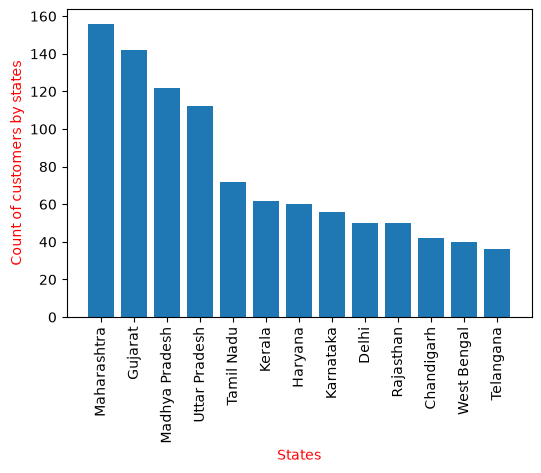

In [99]:
query="""select state, count(customer_id)
from customers group by state"""
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data,columns=["State","No_of_customers"])
df=df.sort_values(by="No_of_customers",ascending=False)
plt.figure(figsize=(6,4))
plt.bar(df["State"],df["No_of_customers"])
plt.xticks(rotation=90)
plt.xlabel("States",color="red")
plt.ylabel("Count of customers by states",color="red")
plt.show()

### Calculate the number of orders per month in 2025.

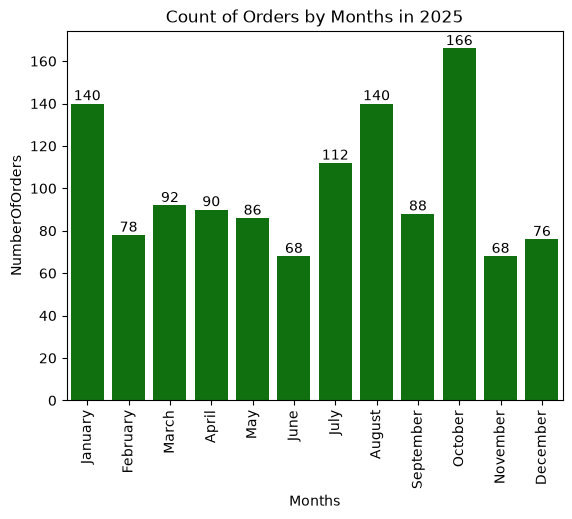

In [106]:
query = """
SELECT 
    MONTHNAME(STR_TO_DATE(order_date, '%d-%m-%Y')) AS order_month_name, 
    COUNT(order_id) AS total_orders
FROM orders 
WHERE RIGHT(order_date, 4) = '2025'
GROUP BY MONTHNAME(STR_TO_DATE(order_date, '%d-%m-%Y'))
"""
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data,columns=["Months","NumberOfOrders"])
o=["January","February","March","April","May","June","July","August","September","October","November","December"]
ax=sns.barplot(x=df["Months"],y=df["NumberOfOrders"],data=df,order=o,color="green")   #hue=df["months"],palette="viridis", containers were removed using this
plt.xticks(rotation=90)
ax.bar_label(ax.containers[0])
plt.title("Count of Orders by Months in 2025")
plt.show()

### Find the average number of products per order, grouped by city.

In [13]:
query="""with count_per_order as
(SELECT orders.order_id,orders.customer_id,count(orders_items.order_id) as oc
from orders join orders_items
on orders.order_id=orders_items.order_id
group by orders.order_id,orders.customer_id)

select customers.city, round(avg(count_per_order.oc),2) average_orders
from customers join  count_per_order
on customers.customer_id=count_per_order.customer_id
group by customers.city order by average_orders desc
 """
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data,columns=["customer_city","average orders/order"])
df


,customer_city,average orders/order
0,Hyderabad,16.62
1,Jaipur,16.11
2,Mumbai,15.82
3,Noida,15.63
4,Nagpur,15.55
5,Kolkata,15.32
6,Kochi,15.22
7,Ahmedabad,15.16
8,Gurugram,14.56
9,Coimbatore,14.55


### Calculate the percentage of total revenue contributed by each product category.

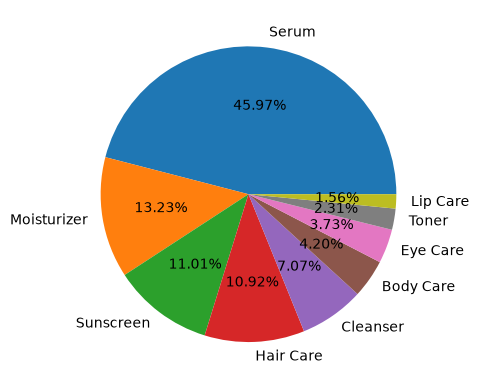

In [44]:
query="""with CategorySales as (SELECT 
    p.category, 
    SUM(oi.item_total) AS total_sales
FROM ecommerce.orders_items oi
JOIN ecommerce.products p 
    ON oi.product_id = p.product_id
GROUP BY p.category)
select category, 
       round(total_sales,2) as total_sales,
       round((total_sales*100.0)/sum(total_Sales)over(),2) as percentage_contribution
from CategorySales
ORDER BY total_sales DESC"""
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data,columns=["Category","Total Sales","Percentage Distribution"])
plt.pie(df["Percentage Distribution"],labels=df["Category"],autopct="%1.2f%%")
plt.show()
            

### Identify the correlation between product price and the number of times a product has been purchased.

In [7]:
query="""SELECT products.category,
count(orders_items.product_id),
round(avg(orders_items.unit_price),2)
from products join orders_items
on products.product_id=orders_items.product_id
group by products.category
 """
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data,columns=["Category","Order Count","Price"])
arr1=df["Order Count"].astype(float)
arr2=df["Price"].astype(float)
a=np.corrcoef([arr1,arr2])
print("The correlation between price and number of times a product has been purchased is",a[0][1])

The correlation between price and number of times a product has been purchased is 0.5582681405584075


### Calculate the total revenue generated by each product and rank them by revenue.

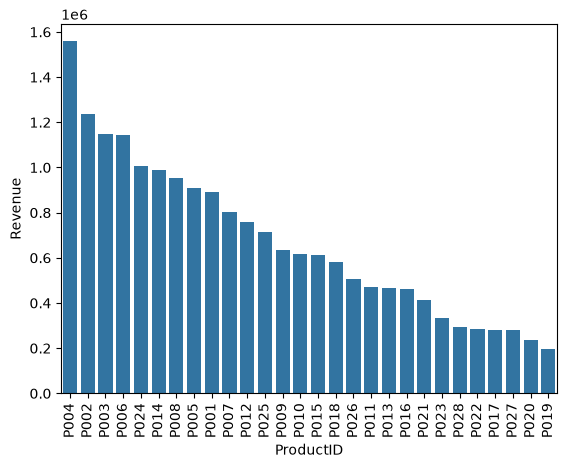

In [15]:
query="""SELECT 
    p.product_id,
    ROUND(SUM(oi.item_total), 2) AS total_revenue,
    RANK() OVER (ORDER BY SUM(oi.item_total) DESC) AS revenue_rank
FROM ecommerce.orders_items oi
JOIN ecommerce.products p 
    ON oi.product_id = p.product_id
GROUP BY p.product_id"""
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data,columns=["ProductID","Revenue","Rank"])
df
sns.barplot(x="ProductID",y="Revenue",data=df)
plt.xticks(rotation=90)
plt.show()

### Calculate the moving average of order values for each customer over their order history.

In [24]:
query="""WITH CustomerOrderValues AS (
    SELECT 
        o.customer_id,
        o.order_id,
        STR_TO_DATE(o.order_date, '%d-%m-%Y') AS parsed_date,
        SUM(oi.item_total) AS order_total
    FROM ecommerce.orders o
    JOIN ecommerce.orders_items oi 
        ON o.order_id = oi.order_id
    GROUP BY o.customer_id, o.order_id, o.order_date
)
SELECT 
    customer_id,
    order_id,
    parsed_date,
    order_total,
    AVG(order_total) OVER (
        PARTITION BY customer_id 
        ORDER BY parsed_date, order_id
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS moving_average_order_value
FROM CustomerOrderValues
ORDER BY customer_id, parsed_date"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["CustomerID","OrderID","OrderDate","OrderTotal","MovingAvg"])
df.head(10)

,CustomerID,OrderID,OrderDate,OrderTotal,MovingAvg
0,C0001,O01021,2024-05-23,15960.000488,15960.000488
1,C0002,O01239,2025-04-04,5025.600098,5025.600098
2,C0002,O00147,2025-09-29,13651.200195,9338.400146
3,C0003,O00303,2024-01-10,11130.399902,11130.399902
4,C0003,O00351,2024-01-14,5304.799805,8217.599854
5,C0003,O01060,2024-12-22,11505.599609,9313.599772
6,C0004,O00476,2025-04-18,7584.799805,7584.799805
7,C0004,O00602,2025-09-30,10624.799805,9104.799805
8,C0005,O00043,2024-05-21,32756.000000,32756.000000
9,C0006,O00965,2024-06-10,20454.400391,20454.400391


### Calculate the cumulative sales per month for each year.

In [31]:
query = """
WITH MonthlySales AS (
    SELECT 
        YEAR(STR_TO_DATE(o.order_date, '%d-%m-%Y')) AS order_year,
        MONTH(STR_TO_DATE(o.order_date, '%d-%m-%Y')) AS order_month_num,
        MONTHNAME(STR_TO_DATE(o.order_date, '%d-%m-%Y')) AS order_month_name,
        SUM(oi.item_total) AS monthly_sales
    FROM ecommerce.orders o
    JOIN ecommerce.orders_items oi 
        ON o.order_id = oi.order_id
    GROUP BY order_year, order_month_num, order_month_name
)
SELECT 
    order_year AS Year,
    order_month_name AS Month,
    ROUND(monthly_sales, 2) AS MonthlySales,
    ROUND(
        SUM(monthly_sales) OVER (
            PARTITION BY order_year 
            ORDER BY order_month_num 
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ), 2
    ) AS CumulativeSales
FROM MonthlySales
ORDER BY order_year, order_month_num
"""

cur.execute(query)
data = cur.fetchall()
df = pd.DataFrame(data, columns=["Year", "Month", "MonthlySales", "CumulativeSales"])
df

,Year,Month,MonthlySales,CumulativeSales
0,2024,January,672148.80,672148.80
1,2024,February,538266.40,1210415.19
2,2024,March,746649.60,1957064.79
3,2024,April,691658.39,2648723.18
4,2024,May,638987.20,3287710.38
5,2024,June,691098.40,3978808.78
6,2024,July,585455.99,4564264.78
7,2024,August,1398180.78,5962445.56
8,2024,September,507781.60,6470227.16
9,2024,October,1418744.79,7888971.95


### Calculate the year-over-year growth rate of total sales.

In [39]:
query = """
WITH YearlySales AS (
    SELECT 
        YEAR(STR_TO_DATE(o.order_date, '%d-%m-%Y')) AS order_year,
        SUM(oi.item_total) AS total_sales
    FROM ecommerce.orders o
    JOIN ecommerce.orders_items oi 
        ON o.order_id = oi.order_id
    GROUP BY order_year
)
SELECT 
    order_year AS Year,
    ROUND(total_sales, 2) AS TotalSales,
    ROUND(LAG(total_sales) OVER (ORDER BY order_year), 2) AS PreviousYearSales,
    ROUND(
        ((total_sales - LAG(total_sales) OVER (ORDER BY order_year)) / LAG(total_sales) OVER (ORDER BY order_year)) * 100, 
        2
    ) AS YoY_Growth_Percentage
FROM YearlySales
ORDER BY order_year
"""

cur.execute(query)
data = cur.fetchall()
df=pd.DataFrame(data,columns=["Year","Total Sales","PY Sales","YoY Growth %"])
df.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white')]}
])

,Year,Total Sales,PY Sales,YoY Growth %
0,2024,9718488.740000,nan,nan
1,2025,9087111.160000,9718488.740000,-6.500000


### Calculate the retention rate of customers,defined as the percentage of customers who make another purchase within 6 months of their first purchase.

In [45]:
query = """
WITH CustomerFirstPurchase AS (
    -- Step 1: Find the first-ever purchase date for each customer
    SELECT 
        customer_id,
        MIN(STR_TO_DATE(order_date, '%d-%m-%Y')) AS first_purchase_date
    FROM ecommerce.orders
    GROUP BY customer_id
),
CustomerRetentionCheck AS (
    -- Step 2: Check if they made another purchase within 6 months of their first purchase
    SELECT 
        cfp.customer_id,
        MAX(
            CASE 
                WHEN STR_TO_DATE(o.order_date, '%d-%m-%Y') > cfp.first_purchase_date 
                 AND STR_TO_DATE(o.order_date, '%d-%m-%Y') <= DATE_ADD(cfp.first_purchase_date, INTERVAL 6 MONTH) 
                THEN 1 
                ELSE 0 
            END
        ) AS retained_within_6m
    FROM CustomerFirstPurchase cfp
    JOIN ecommerce.orders o 
        ON cfp.customer_id = o.customer_id
    GROUP BY cfp.customer_id
)
-- Step 3: Calculate the final retention rate percentage
SELECT 
    COUNT(customer_id) AS total_customers,
    SUM(retained_within_6m) AS retained_customers,
    ROUND((SUM(retained_within_6m) * 100.0) / COUNT(customer_id), 2) AS retention_rate_percentage
FROM CustomerRetentionCheck
"""

cur.execute(query)
data = cur.fetchall()
df=pd.DataFrame(data,columns=["Total Customers","Retained Customers","Retention Rate %"])
df

,Total Customers,Retained Customers,Retention Rate %
0,454,209,46.04


### Identify the top 3 customers who spent the most money in each year.

In [56]:
query = """
WITH CustomerYearlySpending AS (
    -- Step 1: Calculate total spending per customer per year
    SELECT 
        YEAR(STR_TO_DATE(o.order_date, '%d-%m-%Y')) AS order_year,
        c.customer_id,
        c.customer_name, 
        SUM(oi.item_total) AS total_spent
    FROM ecommerce.customers c
    JOIN ecommerce.orders o ON c.customer_id = o.customer_id
    JOIN ecommerce.orders_items oi ON o.order_id = oi.order_id
    GROUP BY order_year, c.customer_id, c.customer_name
),
RankedCustomers AS (
    -- Step 2: Rank customers within each year based on total spending
    SELECT 
        order_year,
        customer_id,
        customer_name,
        total_spent,
        ROW_NUMBER() OVER (PARTITION BY order_year ORDER BY total_spent DESC) AS spending_rank
    FROM CustomerYearlySpending
)
-- Step 3: Keep only the top 3 customers for each year
SELECT 
    order_year AS Year,
    customer_id,
    customer_name,
    ROUND(total_spent, 2) AS TotalSpent,
    spending_rank AS CustomerRank
FROM RankedCustomers
WHERE spending_rank <= 3
ORDER BY order_year DESC, spending_rank ASC;
"""

cur.execute(query)
data = cur.fetchall()
data
df=pd.DataFrame(data,columns=["Year","Customer ID","Customer Name","Total Amount","Rank"])
df
from IPython.display import display, Markdown
for yr in df['Year'].unique():
    df_year = df[df['Year'] == yr]
    display(Markdown(f"### 📊 Top Customers for Year: {yr}"))
    display(df_year)

### 📊 Top Customers for Year: 2025

,Year,Customer ID,Customer Name,Total Amount,Rank
0,2025,C0470,Rohan Agarwal,451923.19,1
1,2025,C0229,Sai Patel,381683.19,2
2,2025,C0434,Ira Singh,375775.99,3


### 📊 Top Customers for Year: 2024

,Year,Customer ID,Customer Name,Total Amount,Rank
3,2024,C0134,Aadhya Mishra,450035.2,1
4,2024,C0280,Reyansh Gupta,447552.0,2
5,2024,C0490,Myra Gupta,442371.2,3
